In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

### Plot embedding results
1. Intrinsic evaluation of 5 embedding models on test data with MRR, MR, hits@1,3,10 for TransE, DistMult, TransR, ComplEx, RotatE
2. MRR for the 5 models on validation data after hyperparameter tuning
3. MRR, MR, Hits@1,3,10 for 3 models - DistMult, TransE, ComplEx - with the best hyperparameters on test data
4. MRR, MR, Hits@1,3,10 for 3 models - DistMult, TransE, ComplEx - with the best hyperparameters on test data using edge weights in training
5. Extrinsic evaluation with 5-fold cross validation classification metrics AUC, precision, recall, F1, accuracy with logistic regression classifier for two edge feature methods - concatenation and hadamard
6. Extrinsic evaluation with 5-fold cross validation classification metrics AUC, precision, recall, F1, accuracy with multilayer perceptron for concatenated features.

colors - https://stackoverflow.com/questions/22408237/named-colors-in-matplotlib

In [2]:
DIR_OUT = '../images/'

In [21]:
models = ['TransE', 'DistMult', 'ComplEx', 'RotatE', 'TransR']
models_sub = ['TransE', 'TransR', 'DistMult', 'ComplEx']
class_metrics = ['AUC', 'Precision', 'Recall', 'F1', 'Accuracy', 'Average Precision']

In [22]:
default_mrr = [0.535210065818949,0.558869122187176,0.533147704297351,0.453913051092948,0.5290744988571303]
best_mrr = [0.677694207769694,0.6316874419213883,0.7175140248818482,0.6554467042643132,0.7109451180212691]
default_mr = [51.588161943361435, 26.4642836962496,32.967064320681345,68.400378134101,52.297934228167236]
best_mr = [27.297116189713005,18.492670080083013,16.021570787936692,37.73938315791096,27.254528748208536]
default_hits = [[0.4335902385025145,0.5993220040786345,0.72339866083124], [0.4365256096120160,0.6359683931515927,0.7902363835765617], 
                [0.4103352159775624,0.614345594920713,0.7553535287379349],[0.3590575606273083,0.5098832401000652,0.6247055960508134], 
                [0.4447541518341013,0.5765829108299558,0.6843479193313916]]
best_hits = [[0.5821733753525142,0.7439648795672743,0.853778836818665],
             [0.516443921345024,0.7104163135103482,0.8422524566837722],
             [0.6263179151705681,0.7852302322355951,0.8708266554684009],
             [0.5767382996101155,0.7057629974367272,0.801154371689962],
             [0.6487468729613249, 0.7486689217302862, 0.8269466618380567]]
validation_mrr = [0.6772161674546304, 0.6476788743632746, 0.6606852801055563, 0.6557565933177638, 0.7123022347452921]

In [23]:
best_mrr_sub = [0.677694207769694,0.6316874419213883,0.7175140248818482]
weights_mrr = [0.19555459514297713,0.3849178755304387,0.4003763595406131]
best_mr_sub = [27.297116189713005,18.492670080083013,16.021570787936692]
weights_mr = [108.27720523647348,68.6238374736096,74.60125858490905]
best_hits_sub = [[0.5821733753525142,0.7439648795672743,0.853778836818665],
             [0.516443921345024,0.7104163135103482,0.8422524566837722],
             [0.6263179151705681,0.7852302322355951,0.8708266554684009]]
weights_hits = [[0.15346985714505865,0.1999763706317774,0.2562922824428657],
                [0.27949304731524144,0.4369651287030045,0.5937970340006061],
                [0.3044778936986639,0.45344115516789696,0.5760358395874107]]

In [24]:
lr_concat = [[0.7788494632245555, 0.8271003518987132, 0.6442795317094824, 0.7045994006575867, 0.6442795317094824, 0.8481541648362967], 
[0.7277267044114859, 0.8107574505947479, 0.5794235143982688, 0.652685465592834, 0.5794235143982688, 0.8228768230050335], 
[0.7641112980407284, 0.806722773968233, 0.7501886478388725, 0.7742859292230324, 0.7501886478388725, 0.8403234374355886], 
[0.7669776492921407, 0.8022894174895931, 0.7688370415580092, 0.7837956177055249, 0.7688370415580092, 0.8401258153692241]]
lr_hadamard = [[0.6495698554161331, 0.2829174247191816, 0.3762414692337569, 0.31062873261691315, 0.3762414692337569, 0.7921718137290027], 
[0.6152707012696742, 0.7687766029232604, 0.3599622704322255, 0.37825005256423117, 0.3599622704322255, 0.7717685320998663], 
[0.6823705725911351, 0.7901725049786882, 0.6196609887366143, 0.6825388065545726, 0.6196609887366143, 0.8070679050519663], 
[0.695374365671155, 0.7884913176242788, 0.6964739499528381, 0.732730102459719, 0.6964739499528381, 0.8050825865548485]]
mlp_concat = [[0.7886065502286925, 0.8068406053762966, 0.829958941352716, 0.8159721365948446, 0.829958941352716, 0.8548799083278386], 
[0.743999266544584, 0.7842615549135289, 0.8038783776285857, 0.7926473745719811, 0.8038783776285857, 0.8266703785817742], 
[0.7675213868299428, 0.8001592001422339, 0.8337097042667704, 0.8124864675822238, 0.8337097042667704, 0.8456953965363943], 
[0.7936400602152436, 0.8056482596208021, 0.832206070021639, 0.8148546698778418, 0.832206070021639, 0.8565755496506517]]

In [6]:
def plot_comparison_bar(metric, baseline, best, models):
    x = np.arange(len(models))  # Label locations
    width = 0.35  # Width of the bars

    fig, ax = plt.subplots(figsize=(10, 6))
    bars1 = ax.bar(x - width/2, baseline, width, label='No weights', color='#4682B4')
    bars2 = ax.bar(x + width/2, best, width, label='With weights', color='#FA8072')

    ax.set_xlabel('Models')
    ax.set_ylabel(metric)
    ax.set_xticks(x)
    ax.set_xticklabels(models)
    ax.legend()
    ax.grid(True)
    # Adjust legend position to avoid overlap
    ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
    #fig.savefig(DIR_OUT + filename + '.png')
    plt.tight_layout()
    plt.show()

In [7]:
def plot_hits(models, hits):
    x = np.arange(len(models))  # Label locations
    width = 0.2  # Width of the bars

    fig, ax = plt.subplots(figsize=(12, 6))
    bars1 = ax.bar(x - width, [h[0] for h in hits], width, label='Hits@1', color='#4682B4')
    bars2 = ax.bar(x, [h[1] for h in hits], width, label='Hits@3', color='#FA8072')
    bars3 = ax.bar(x + width, [h[2] for h in hits], width, label='Hits@10', color='#3CB371')

    ax.set_xlabel('Models')
    ax.set_ylabel('Hits@k')
    ax.set_xticks(x)
    ax.set_xticklabels(models)
    ax.legend()
    ax.grid(True)
    ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
    plt.tight_layout()
    plt.show()

In [39]:
def plot_validation_mrr(models, validation_mrr):
    x = np.arange(len(models))
    width = 0.5

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.bar(x, validation_mrr, width, color='#4682B4')

    ax.set_xlabel('Models')
    ax.set_ylabel('MRR')
    ax.set_xticks(x)
    ax.set_xticklabels(models)
    ax.grid(True)
    ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
    #fig.savefig(DIR_OUT + filename + '.png')
    plt.tight_layout()
    plt.show()

In [25]:
def plot_classification_metrics_grid(models, metrics, concat_values, hadamard_values):
    x = np.arange(len(models))
    width = 0.35

    fig, axs = plt.subplots(1, len(metrics), figsize=(20, 6), sharey=True)
    for i, metric in enumerate(metrics):
        ax = axs[i]
        #bars1 = ax.bar(x - width/2, [v[i] for v in concat_values], width, label='Concatenation')
        #bars2 = ax.bar(x + width/2, [v[i] for v in hadamard_values], width, label='Hadamard')
        bars1 = ax.bar(x - width/2, [v[i] for v in concat_values], width, label='Multilayer Perceptron', color='#4682B4')
        bars2 = ax.bar(x + width/2, [v[i] for v in hadamard_values], width, label='Logistic Regression', color='#FA8072')
        ax.set_xlabel('Models')
        ax.set_xticks(x)
        ax.set_xticklabels(models)
        ax.legend()
        ax.grid(True)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    #fig.savefig(DIR_OUT + filename + '.png')
    plt.show()

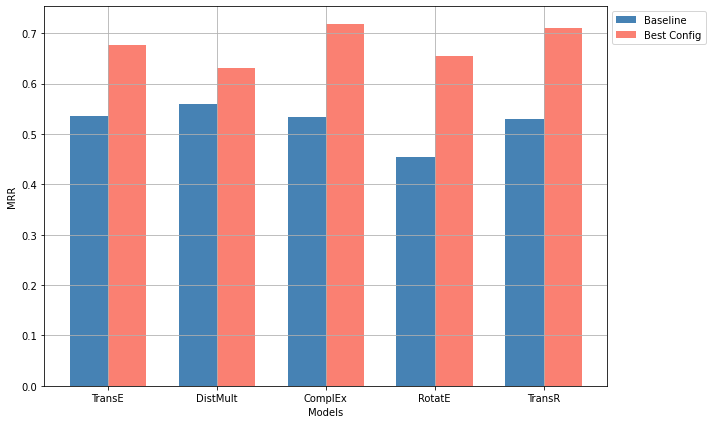

In [28]:
plot_comparison_bar('MRR', default_mrr, best_mrr, models)

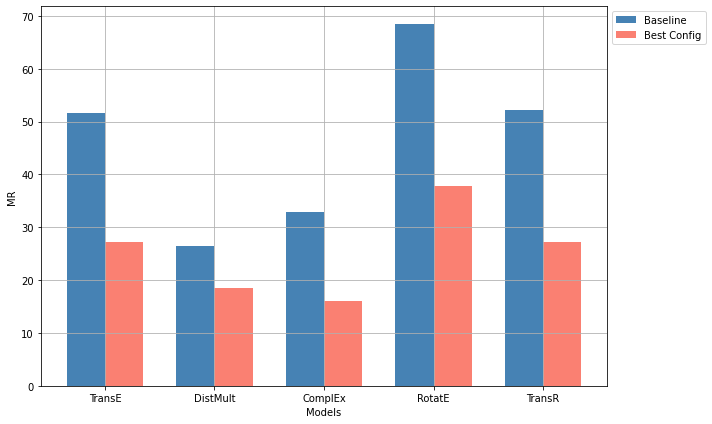

In [29]:
plot_comparison_bar('MR', default_mr, best_mr, models)

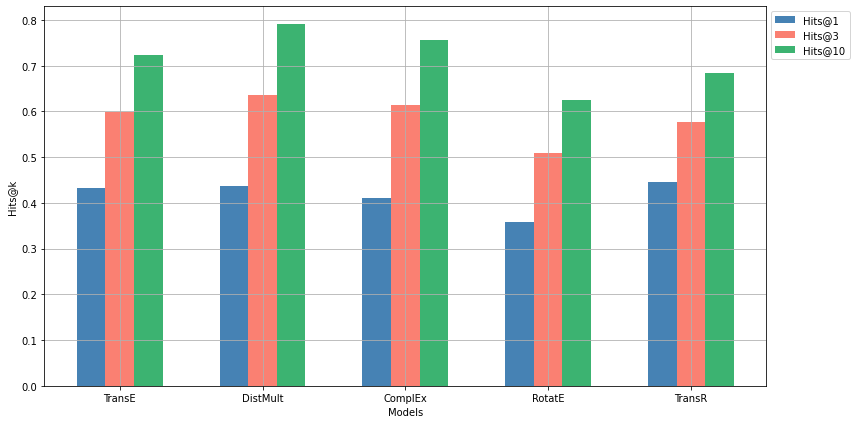

In [44]:
plot_hits(models, default_hits)

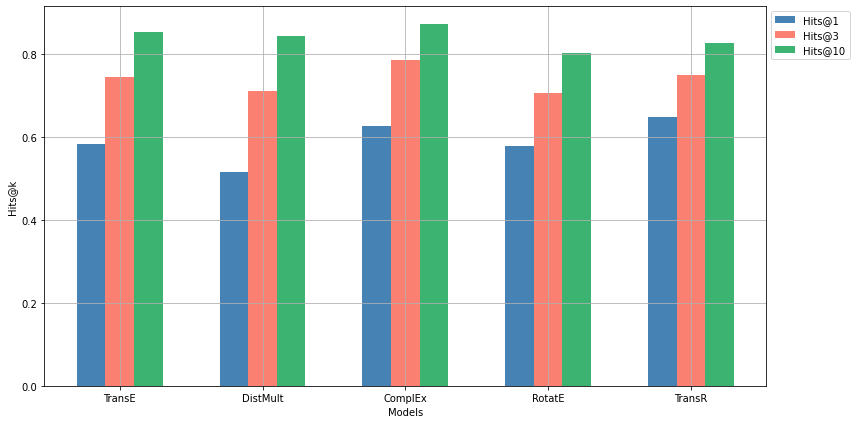

In [45]:
plot_hits(models, best_hits)

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


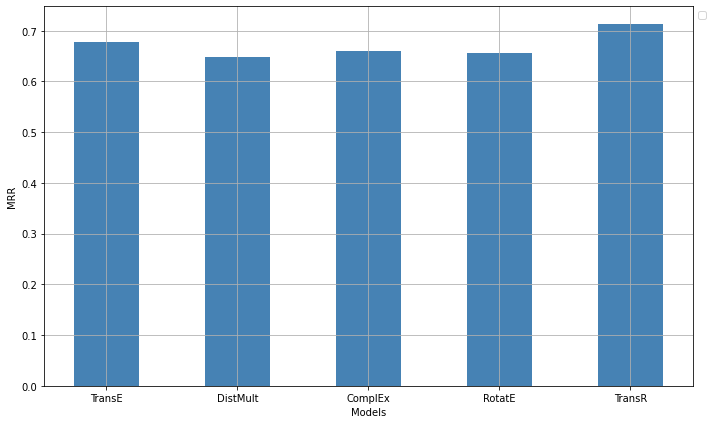

In [31]:
plot_validation_mrr(models, validation_mrr)

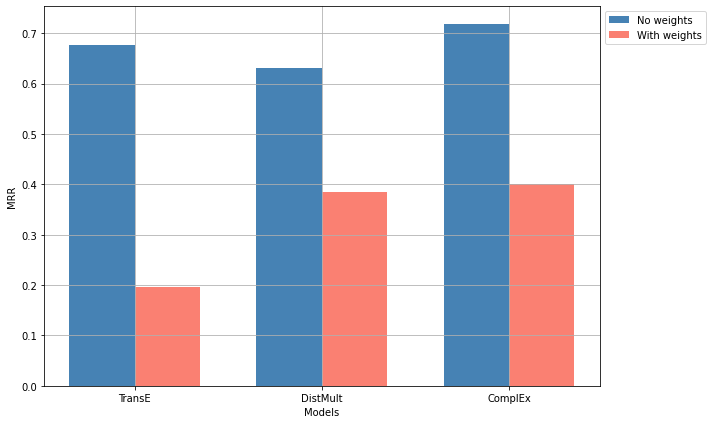

In [42]:
plot_comparison_bar('MRR', best_mrr_sub, weights_mrr, models_sub)

In [ ]:
plot_comparison_bar('MR', best_mr, weights_mr, 'Comparison of MR for 3 Models with and without Edge Weights')
plot_comparison_hits(models_sub, best_hits, weights_hits, 'Comparison of Hits@k for 3 Models with and without Edge Weights')

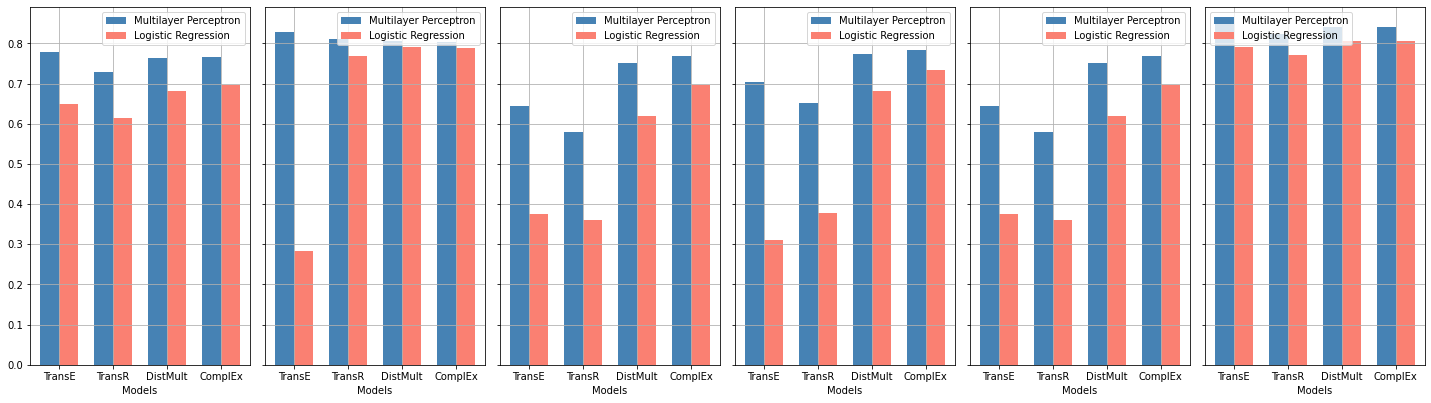

In [26]:
plot_classification_metrics_grid(models_sub, class_metrics, lr_concat, lr_hadamard)

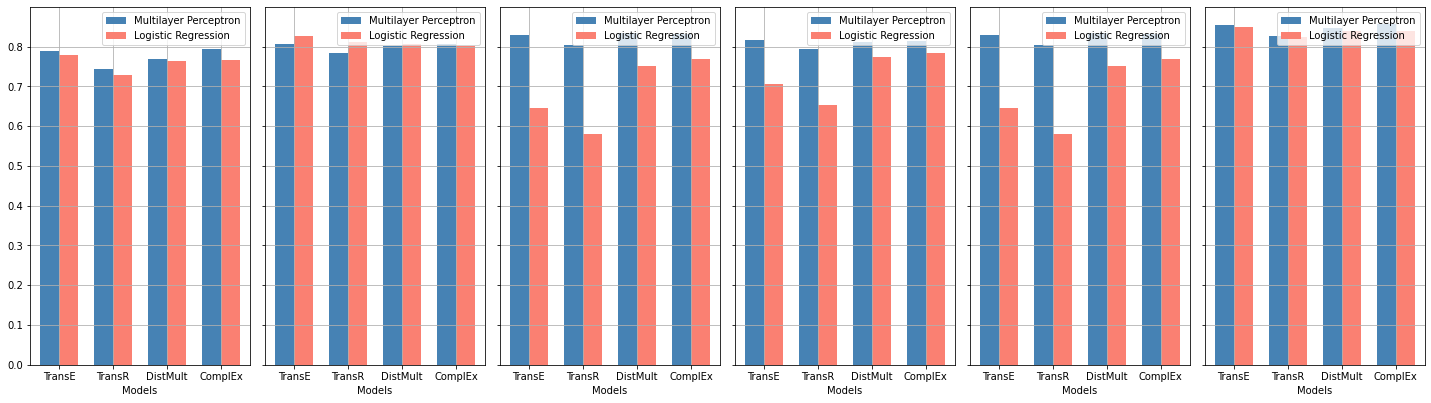

In [27]:
plot_classification_metrics_grid(models_sub, class_metrics, mlp_concat, lr_concat)

In [28]:
def plot_individual_classification_metric(metric, concat_values, hadamard_values, models):
    x = np.arange(len(models))
    width = 0.35

    fig, ax = plt.subplots(figsize=(8, 6))
    bars1 = ax.bar(x - width/2, [v[class_metrics.index(metric)] for v in concat_values], width, label='Concatenate', color='#4682B4')
    bars2 = ax.bar(x + width/2, [v[class_metrics.index(metric)] for v in hadamard_values], width, label='Hadamard', color='#FA8072')

    ax.set_xlabel('Models')
    ax.set_ylabel(metric)
    ax.set_xticks(x)
    ax.set_xticklabels(models)
    ax.legend()
    ax.grid(True)

    # Adjust legend position to avoid overlap
    ax.legend(loc='upper left', bbox_to_anchor=(1, 1))

    plt.tight_layout()
    plt.show()

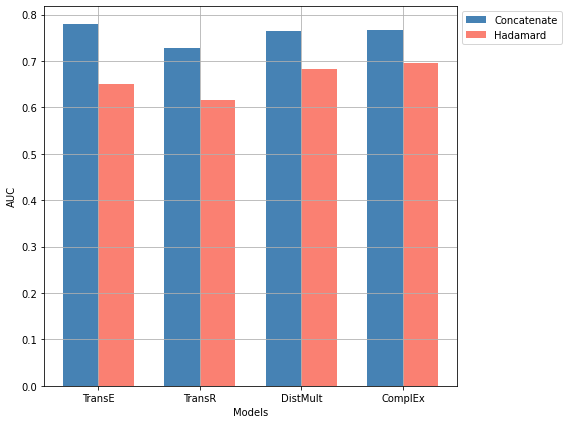

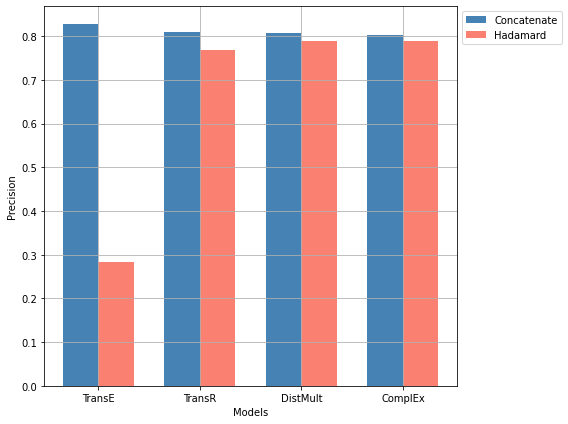

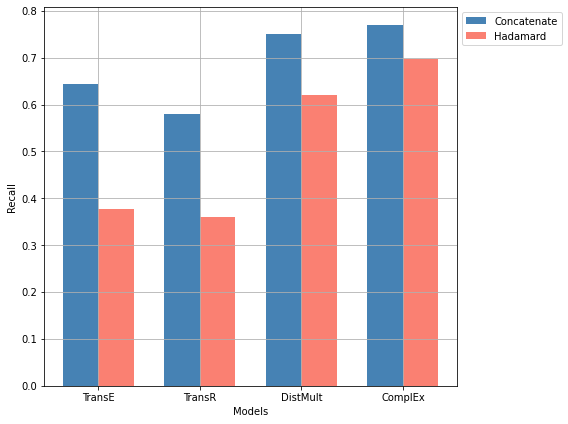

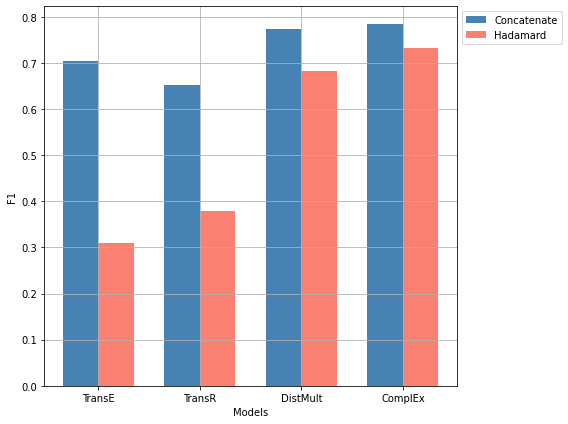

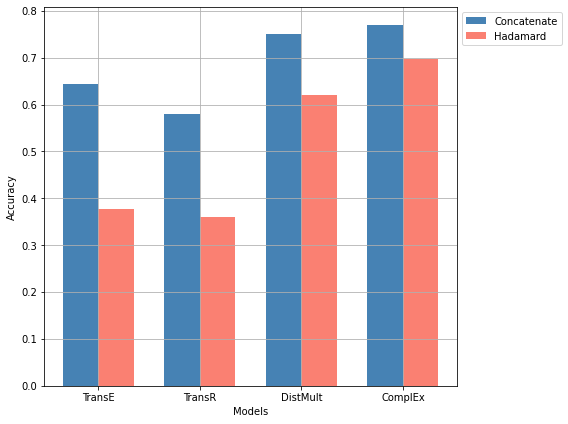

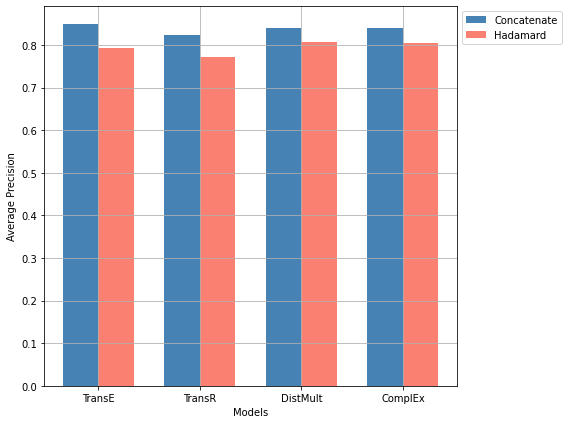

In [29]:
for metric in class_metrics:
    plot_individual_classification_metric(metric, lr_concat, lr_hadamard, models_sub)

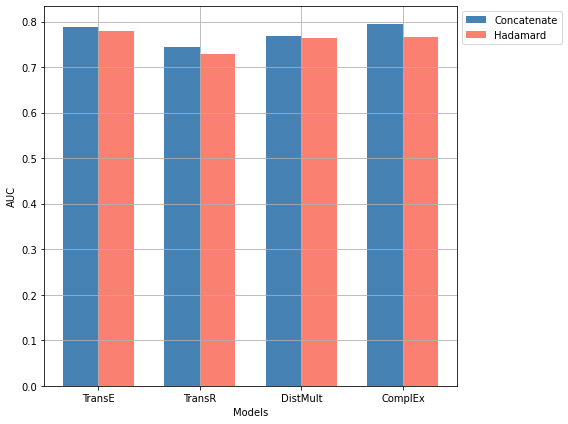

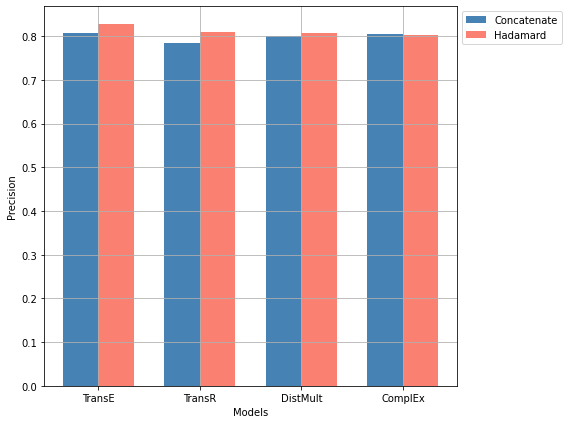

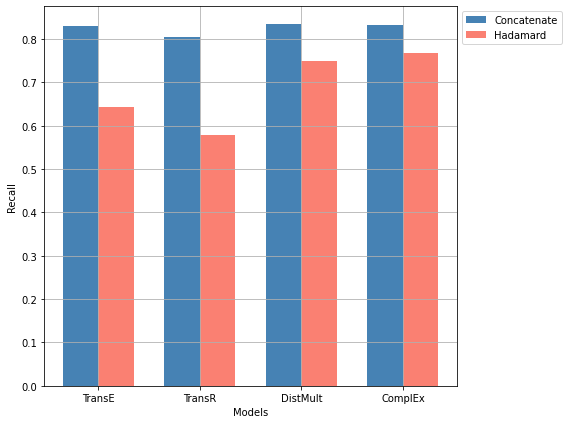

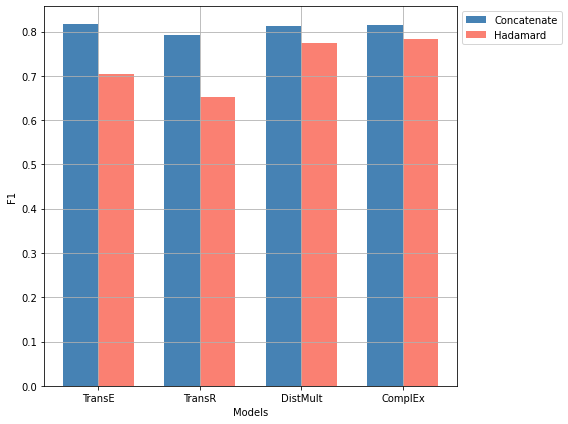

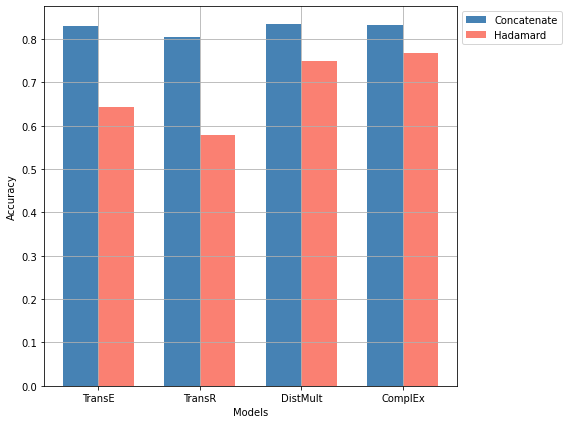

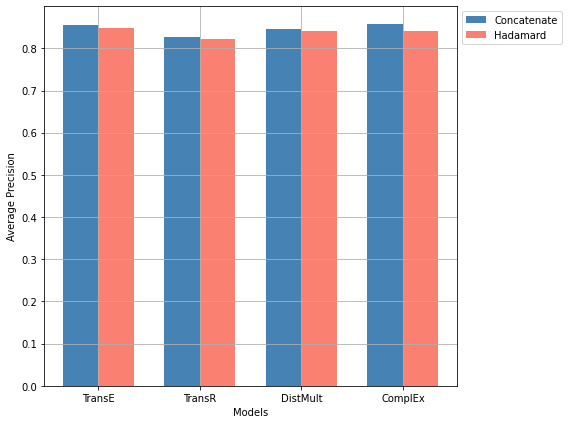

In [30]:
for metric in class_metrics:
    plot_individual_classification_metric(metric, mlp_concat, lr_concat, models_sub)